## Post-stack inversion - Volve model

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import random
import warnings
warnings.filterwarnings('ignore')
import collections
import time

import numpy as np
import scipy as sp
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import segyio
import torch

from scipy.signal import filtfilt
from scipy.linalg import solve
from scipy.sparse.linalg import lsqr
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RegularGridInterpolator
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

from pylops.basicoperators import *
from pylops.signalprocessing import *
from pylops.utils.wavelets import *
from pylops.avo.poststack import *
from pylops.optimization.sparsity import *
from pylops.basicoperators import VStack as VStacklop

from pyproximal.proximal import *
from pyproximal import ProxOperator
from pyproximal.optimization.primal import *
from pyproximal.optimization.primaldual import *
from pyproximal.optimization.bregman import *
from pyproximal.optimization.segmentation import *

from torch.optim.lr_scheduler import CosineAnnealingLR, LambdaLR, ReduceLROnPlateau
from torch.optim import Adam, SGD, RMSprop, RAdam
from pnpsvgd.model import UNetRes
from pnpsvgd.denoiser import *
from pnpsvgd.pnpseismic import *
from pnpsvgd.utils import *
from pnpsvgd.svgd import *

# random seed
np.random.seed(10)
random.seed(10)
torch.manual_seed(10)
torch.cuda.manual_seed_all(10)

# plotting setting
plt.style.use('seaborn-ticks')
matplotlib.rc('xtick', labelsize=13) 
matplotlib.rc('ytick', labelsize=13) 
plt.rc('font', size=15)
plt.rc('axes', titlesize=15)
plt.rc('axes', labelsize=15)

# gpu setting
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
device = torch.device('cuda')

print("Current working directory: {0}".format(os.getcwd()))

Current working directory: /home/izzatum/Desktop/pnp-svgd/notebooks


In [2]:
cmap_ai = LinearSegmentedColormap.from_list('name', ['#800000', '#ffdb4d',
                                                     '#006600', '#0099cc',
                                                     '#0059b3'])

In [3]:
def vint2vrms(vint, t):
    nt = t.size
    dt = np.diff(t)
    vrms = np.zeros(nt)
    vrms[:-1] = np.cumsum(dt * (vint[:-1]**2));
    vrms[:-1] = np.sqrt(vrms[:-1] / t[:-1]-t[0])
    vrms[-1] = vrms[-2]
    return vrms

def vrms2vint(vrms, t):
    nt = t.size
    i1 = np.arange(0, nt-1)
    i2 = np.arange(1, nt)
    vint = np.zeros(nt)
    vrms2 = vrms ** 2
    vint[i1]= np.sqrt((vrms2[i2]*(t[i2] - t[0]) - vrms2[i1]*(t[i1] - t[0])) / (t[i2] - t[i1]))

    #find and process non-physical ones
    inp = np.where(vint<0);
    if len(inp):
        vint[inp] = np.nan
    return vint

## Load data

In [4]:
f = np.load('../data/Volve2dfence_NO_15_9-19_BT2.npz', allow_pickle=True)

In [5]:
t_seis = f['t_seis']
t_vrms = f['t_vrms']
t_ainvt = f['t_ainvt']
dt = t_seis[1] - t_seis[0]

seismic_fence = f['seismict_fence']
vrms_fence = f['vrms_fence']
aiinvt_fence = f['aiinvt_fence']
x_seis = np.arange(seismic_fence.shape[0])

horizons_fence = f['horizons_fence'][()]

well_tvdss = f['well_tvdss']
well_twt = f['well_twt']
well_ai = f['well_ai']
twell = f['twell']
twell_int = f['twell_int']
dtwell_int = twell_int[1] - twell_int[0]
xfence = f['xfence']
xfence_int = f['xfence_int']

## Compute interval velocities from RMS

Given that we have access to only RMS velocities in time, we need to estimate interval velocities from them

In [6]:
vint_fence = np.zeros_like(vrms_fence)
for ifence in range(len(x_seis)):
    vint_fence[ifence] = vrms2vint(vrms_fence[ifence], t_vrms / 1000)
vint_fence = gaussian_filter(vint_fence, sigma=30)

We now regrid the RMS velocities to the same grid as our data

In [7]:
IL, T = np.meshgrid(x_seis, t_seis, indexing='ij')

vinterp = RegularGridInterpolator((x_seis, t_vrms), vint_fence, bounds_error=False, fill_value=0)
vint_fence = vinterp(np.vstack((IL.ravel(), T.ravel())).T)
vint_fence = vint_fence.reshape(seismic_fence.shape)

## Estimate wavelet

Window data and velocity model to area of interest

In [8]:
tmin, tmax = 1900, 3200
itmin, itmax = int((tmin-t_seis[0])/dt), int((tmax-t_seis[0])/dt)

vint_fence = vint_fence[:, itmin:itmax]
seismic_fence = seismic_fence[:, itmin:itmax]
t_cut = t_seis[itmin:itmax]

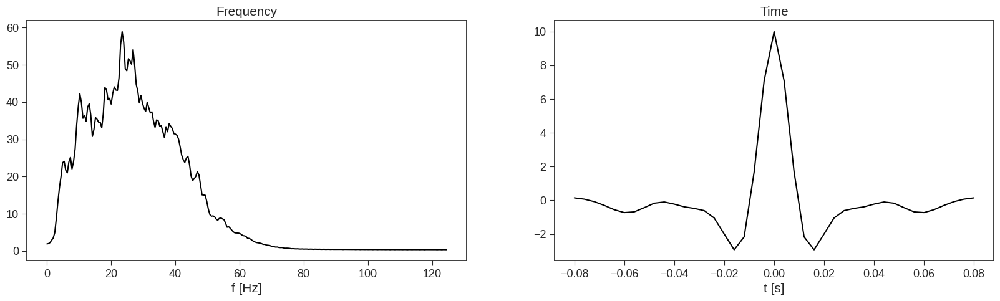

In [9]:
nt_wav = 21 # number of samples of statistical wavelet
nfft = 512 # number of samples of FFT
wav_scaling = 1e1

# Wavelet time axis
t_wav = np.arange(nt_wav) * (dt/1000)
t_wav = np.concatenate((np.flipud(-t_wav[1:]), t_wav), axis=0)

# Estimate wavelet spectrum
wav_est_fft = np.mean(np.abs(np.fft.fft(seismic_fence, nfft, axis=-1)), axis=0)
fwest = np.fft.fftfreq(nfft, d=dt/1000)

# Create wavelet in time
wav_est = np.real(np.fft.ifft(wav_est_fft)[:nt_wav])
wav_est = np.concatenate((np.flipud(wav_est[1:]), wav_est), axis=0)
wav_est = wav_est / wav_est.max()
wav_est *= wav_scaling

# Display wavelet
fig, axs = plt.subplots(1, 2, figsize=(20, 5))
# fig.suptitle('Statistical wavelet estimate')
axs[0].plot(fwest[:nfft//2], wav_est_fft[:nfft//2], 'k')
axs[0].set_title('Frequency')
axs[0].set_xlabel('f [Hz]')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')

axs[1].plot(t_wav, wav_est, 'k')
axs[1].set_title('Time')
axs[1].set_xlabel('t [s]')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')
# plt.savefig('../figures/volve/3-2-volve-wavelet.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-wavelet.png', dpi=300, bbox_inches="tight")

## Post-stack inversion

Convert background velocities to AI

In [10]:
intercept = -3952.2622879733026
gradient = 3.3952561093488325

ai_fence = np.log(intercept + gradient*vint_fence)

ai_fence_t = RegularGridInterpolator((x_seis, t_cut), 
                                     ai_fence, 
                                     bounds_error=False, 
                                     fill_value=np.nan)(np.vstack((x_seis, twell)).T)

In [11]:
nt = itmax - itmin
nfence = x_seis.size

Lop = PoststackLinearModelling(wav_est, nt0=nt, spatdims=nfence)
Lop_torch = TorchOperator(Lop, batch=True)

In [12]:
mback = ai_fence.T
dback = Lop * mback.ravel()
dback = dback.reshape(nt, nfence)
dtorch = torch.from_numpy(seismic_fence.T.ravel())

### DRUNET

In [13]:
model_02 = UNetRes(in_nc=2)
model_02.load_state_dict(torch.load('../models/drunet_gray.pth'))
model_02.eval().to(device).half();

## SVGD with Gaussian + TV prior

In [14]:
num_particles = 100

# prior
x0 = torch.from_numpy(mback.ravel())
sigma0 = 0.5*torch.ones(nt*nfence) # with smooth
prior = torch.distributions.Normal(x0, sigma0)

# likelihood ** very large impact on the choice of noise std vs prior std)

# likelihood
Cd = 1e-2*torch.ones(nt*nfence)
likelihood = torch.distributions.Normal(dtorch, Cd)

# prior TV
Gop = Gradient(dims=(nt, nfence), edge=True, dtype=Lop.dtype, kind='forward')
Gop_torch = TorchOperator(Gop, batch=True)

sigmatv = 0.3*torch.ones(2*nt*nfence)
prior1 = torch.distributions.Laplace(torch.zeros(2*nt*nfence), sigmatv)

# posterior
gpost = PosteriorDistribution(x0, sigma0, dtorch, Lop_torch, Cd, 
                              xtv=torch.zeros(2*nt*nfence), Gtv=Gop_torch, Ctv=sigmatv,
                              verb=False)

# SVGD Kernel
K = RBF()

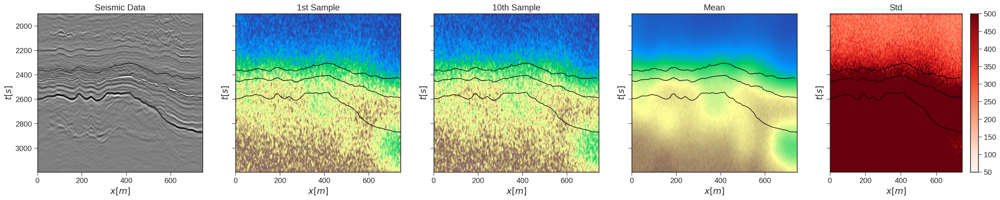

In [15]:
# prior samples
X_init = prior.sample_n(num_particles)
X_init = torch.from_numpy(np.vstack([sp.ndimage.gaussian_filter(X_init[i].numpy().reshape(nt,nfence), 2).ravel()
                                     for i in range(num_particles)]))

fig, axs = plt.subplots(1, 5, sharey=True, figsize=(30, 5), dpi=150)
axs[0].imshow(seismic_fence.T, cmap='gray', vmin=-10, vmax=10, interpolation='sinc',
              extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[0].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[0].set_title('Seismic Data')
axs[0].set_ylabel(r'$t [s]$')
axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')

axs[1].imshow(np.exp(X_init[0].detach().numpy().reshape(nt, nfence)), cmap='terrain', 
              vmin=3000, vmax=15000, interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[1].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[1].set_title('1st Sample')
axs[1].set_ylabel(r'$t [s]$')
axs[1].set_xlabel(r'$x [m]$')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')

axs[2].imshow(np.exp(X_init[10].detach().numpy().reshape(nt, nfence)), cmap='terrain', 
              vmin=3000, vmax=15000, interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[2].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[2].set_title('10th Sample')
axs[2].set_ylabel(r'$t [s]$')
axs[2].set_xlabel(r'$x [m]$')
axs[2].axis('tight')
axs[2].set_aspect('auto', 'datalim')

axs[3].imshow(torch.exp(X_init).mean(0).detach().numpy().reshape(nt, nfence), cmap='terrain', 
              vmin=3000, vmax=15000, interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[3].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[3].set_title('Mean')
axs[3].set_ylabel(r'$t [s]$')
axs[3].set_xlabel(r'$x [m]$')
axs[3].axis('tight')
axs[3].set_aspect('auto', 'datalim')

im = axs[4].imshow(torch.exp(X_init).std(0).detach().numpy().reshape(nt, nfence), cmap='Reds', vmin=50, vmax=500, 
              interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[4].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[4].set_title('Std')
axs[4].set_ylabel(r'$t [s]$')
axs[4].set_xlabel(r'$x [m]$')
axs[4].axis('tight')
axs[4].set_aspect('auto', 'datalim')
plt.colorbar(im, ax=axs[4]);

Iter 0: LogP=280342021748.521
Iter 10: LogP=28267000612.078
Iter 20: LogP=25825209166.949
Iter 30: LogP=31596575213.788
Iter 40: LogP=18227051976.869
Iter 50: LogP=8029211526.902
Execution time: 796.0053424835205 seconds


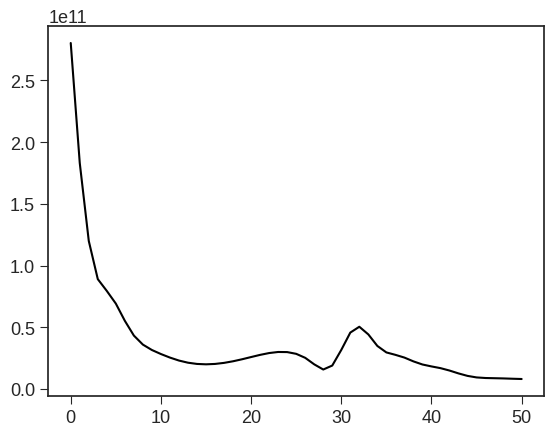

In [16]:
X = X_init.clone()
mu = .5 
sigma = 0.0009
lr = 1e-1
niter = 51

denoiser_dn = lambda x: apply_DRUNET(model_02,
                                     x.to(device),
                                     mu,
                                     sigma,
                                     mback.shape,
                                     edge_max=1024,
                                     verb=False)
optimizer = Adam([X], lr=lr)

scheduler = CosineAnnealingLR(optimizer, 20, eta_min=0, last_epoch=- 1, verbose=False)
svgd = PnPSVGD(denoiser_dn, gpost, K, optimizer, scheduler=scheduler, loops=10)
log_prob = []
Xmeancol = []
Xstdcol = []

# get the start time
st = time.time()
for iiter in range(niter):
    lp = svgd.step(X)
    log_prob.append(-lp)
    if iiter % 10 == 0:
        print(f'Iter {iiter}: LogP={-lp:.3f}')
        Xmeancol.append(torch.exp(X).mean(0).detach().numpy())
        Xstdcol.append(torch.exp(X).std(0).detach().numpy())

# get the end time
et = time.time()

# get the execution time
elapsed_time = et - st
print('Execution time:', elapsed_time, 'seconds')

plt.figure()
plt.plot(log_prob, 'k');

## Optimization

In [17]:
l2 = L2(Op=Lop, b=seismic_fence.T.ravel(), x0=ai_fence.T.ravel(), niter=20, warm=True)
Iop = Identity(ai_fence.size)

L = 1.
tau = 6.
mu = 0.1 #tau*mu*L<=1 
sigma = mu

denoiser_dn = lambda x, tau: apply_DRUNET_optimization(model_02,
                                                       torch.from_numpy(x),
                                                       mu,
                                                       sigma,
                                                       edge_max=1024,
                                                       verb=False)

mdrunet = PlugAndPlay_PrimalDual(l2, denoiser_dn, Iop, (nt, nfence),
                                 tau=tau, mu=mu, x0=mback.ravel(), 
                                 niter=100,  show=True)
mdrunet = mdrunet.reshape(nt, nfence)

mdrunet_t = RegularGridInterpolator((x_seis, t_cut), 
                                    np.exp(mdrunet).T, 
                                    bounds_error=False,
                                    fill_value=np.nan)(np.vstack((xfence_int, twell_int)).T)

Primal-dual: min_x f(Ax) + x^T z + g(x)
---------------------------------------------------------
Proximal operator (f): <class 'pyproximal.proximal.L2.L2'>
Proximal operator (g): <class 'pnpsvgd.pnpseismic._Denoise'>
Linear operator (A): <class 'pylops.basicoperators.Identity.Identity'>
Additional vector (z): None
tau = 6.000000e+00	mu = 1.000000e-01
theta = 1.00		niter = 100

   Itn       x[0]          f           g          z^x       J = f + g + z^x
     1   8.26564e+00   8.803e+03   0.000e+00   0.000e+00       8.803e+03
     2   8.24849e+00   5.742e+03   0.000e+00   0.000e+00       5.742e+03
     3   8.24318e+00   4.652e+03   0.000e+00   0.000e+00       4.652e+03
     4   8.23979e+00   4.163e+03   0.000e+00   0.000e+00       4.163e+03
     5   8.24341e+00   3.771e+03   0.000e+00   0.000e+00       3.771e+03
     6   8.24108e+00   3.532e+03   0.000e+00   0.000e+00       3.532e+03
     7   8.24299e+00   3.306e+03   0.000e+00   0.000e+00       3.306e+03
     8   8.24072e+00   3.154e+03

## Save parameters

In [18]:
np.savez('../figures/volve/volve_results',
        X_init=X_init.detach().numpy(),
        X=X.detach().numpy(),
        Xmeancol=Xmeancol,
        Xstdcol=Xstdcol,
        minv_t=minv_t,
        well_ai_int=well_ai_int,
        mdrunet=mdrunet,
        mdrunet_t=mdrunet_t)

## Plotting

In [19]:
plt.rcParams['font.size'] = '15'

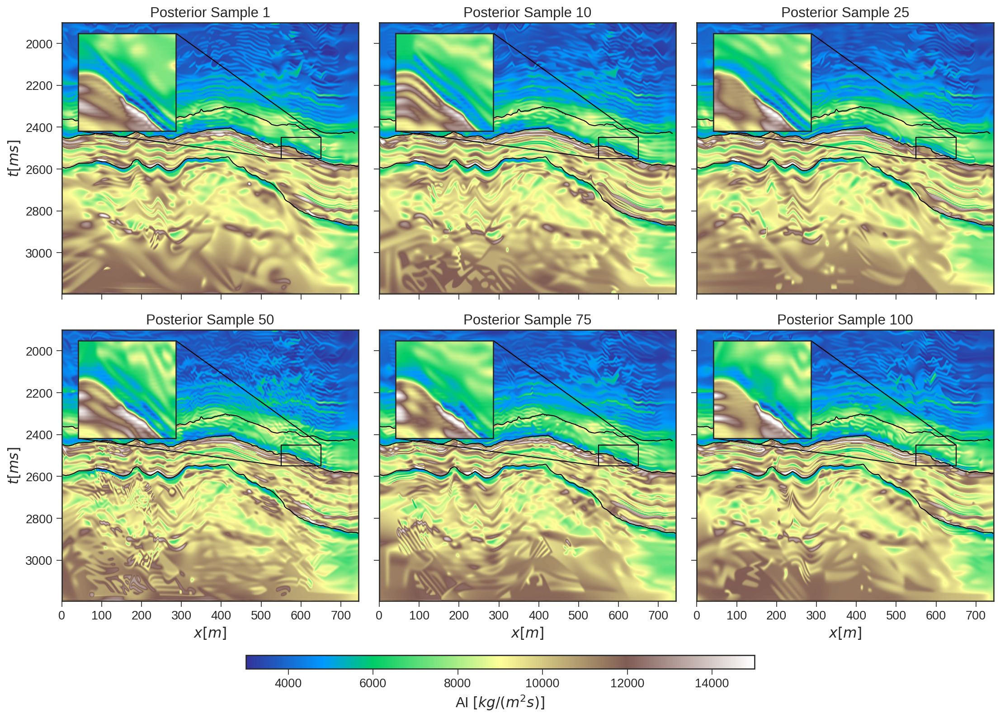

In [20]:
iiter = np.array([1, 10, 25, 50, 75, 100])
fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(15,10), dpi=150)
axs = axs.ravel()
vmin, vmax = 3000, 15000
for i, k in enumerate(iiter):
    axi=axs[i].imshow(np.exp(X[i]).reshape(nt, nfence), vmin=vmin, vmax=vmax, cmap="terrain",
                     interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
    for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
        axs[i].plot(x_seis, horizons_fence[horname], 'k', lw=1)
    axs[i].set_title('Posterior Sample %d' % k)
    axs[i].axis('tight')
    axs[i].set_aspect('auto', 'datalim')
    
    axins = axs[i].inset_axes([0.04, 0.6, 0.36, 0.36])
    axins.imshow(np.exp(X[i]).reshape(nt, nfence), 
                 vmin=vmin, vmax=vmax, cmap="terrain",
                 interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
    # sub region of the original image
    x1, x2, y1, y2 = 550, 650, 2450, 2550
    axins.set_xlim(x1, x2)
    axins.set_ylim(y2, y1)
    axins.set_xticklabels([])
    axins.set_yticklabels([])
    axins.set_xticks([])
    axins.set_yticks([])

    _patch, pp1, pp2 = mark_inset(axs[i], axins, loc1=1, loc2=3, fc="none", ec="black")
    pp1.loc1, pp1.loc2 = 1, 4  # inset corner 1 to origin corner 4 (would expect 1)
    pp2.loc1, pp2.loc2 = 3, 2  # inset corner 3 to origin corner 2 (would expect 3)

axs[0].set_ylabel(r'$t [ms]$')
axs[3].set_ylabel(r'$t [ms]$')
axs[3].set_xlabel(r'$x [m]$')
axs[4].set_xlabel(r'$x [m]$')
axs[5].set_xlabel(r'$x [m]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)
cbar_ax = fig.add_axes([0.25, 0.0001, 0.5, 0.02])
cbar = fig.colorbar(axi, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'AI $[kg/(m^2s)]$')
# plt.savefig('../figures/volve/3-2-volve-samples.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-samples.png', dpi=300, bbox_inches="tight")

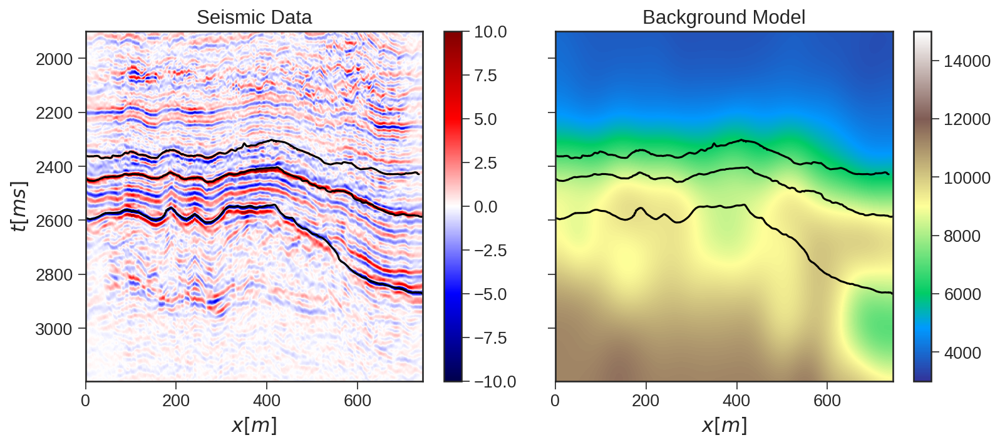

In [21]:
fig, axs = plt.subplots(1, 2, sharey=True, figsize=(11, 5), dpi=150)
im1 = axs[1].imshow(np.exp(mback), vmin=3000, vmax=15000, cmap="terrain",
                     interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[1].plot(x_seis, horizons_fence[horname], 'k', lw=1.5)
axs[1].set_title('Background Model')
axs[1].axis('tight')
# axs[1].set_ylabel(r'$t [ms]$')
axs[1].set_xlabel(r'$x [m]$')
axs[1].set_aspect('auto', 'datalim')
plt.colorbar(im1, ax=axs[1])

im2 = axs[0].imshow(seismic_fence.T, cmap='seismic', vmin=-10, vmax=10, interpolation='sinc',
              extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[0].plot(x_seis, horizons_fence[horname], 'k', lw=1.5)
axs[0].set_title(r'Seismic Data')
axs[0].set_ylabel(r'$t [ms]$')
axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')
plt.colorbar(im2, ax=axs[0])

fig.tight_layout()

# plt.savefig('../figures/volve/3-2-volve-data-model.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-data-model.png', dpi=300, bbox_inches="tight")

(0.0, 744.0, 3196.0, 1900.0)

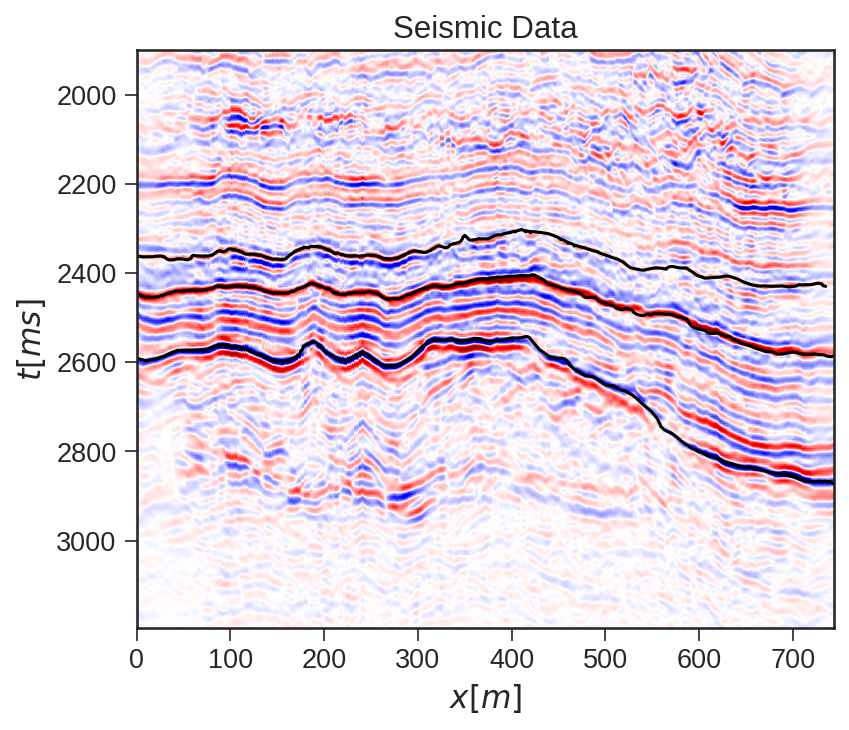

In [22]:
plt.figure(figsize=(6, 5), dpi=150)
plt.imshow(seismic_fence.T, cmap='seismic', vmin=-10, vmax=10, interpolation='sinc',
              extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    plt.plot(x_seis, horizons_fence[horname], 'k', lw=1.5)
plt.title('Seismic Data')
plt.ylabel(r'$t [ms]$')
plt.xlabel(r'$x [m]$')
plt.axis('tight')

# plt.savefig('../figures/volve/3-2-volve-data.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-data.png', dpi=300, bbox_inches="tight")

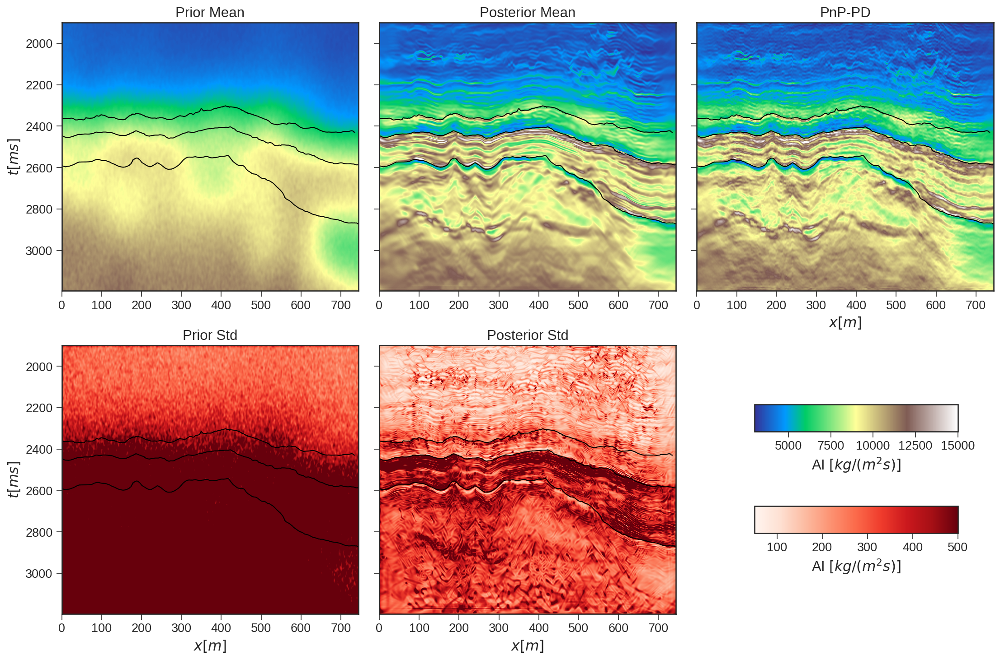

In [23]:
fig, axs = plt.subplots(2, 3, sharey=True, figsize=(15, 10), dpi=150)
axs = axs.ravel()
axi = axs[0].imshow(np.exp(X_init).mean(0).reshape(nt, nfence), cmap='terrain', 
                    vmin=3000, vmax=15000, interpolation='sinc', 
                    extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[0].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[0].set_title('Prior Mean')
axs[0].set_ylabel(r'$t [ms]$')
axs[0].set_aspect('auto', 'datalim')
# axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')

axs[1].imshow(np.exp(X).mean(0).reshape(nt, nfence), cmap='terrain', vmin=3000, vmax=15000, 
              interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[1].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[1].set_title('Posterior Mean')
# axs[1].set_ylabel(r'$t [ms]$')
# axs[1].set_xlabel(r'$x [m]$')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')

im = axs[2].imshow(np.exp(mdrunet.reshape(nt, nfence)), cmap='terrain', vmin=3000, vmax=15000, 
              interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[2].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[2].set_title('PnP-PD')
# axs[2].set_ylabel(r'$t [ms]$')
axs[2].set_xlabel(r'$x [m]$')
axs[2].axis('tight')
axs[2].set_aspect('auto', 'datalim')

# std
axi2 = axs[3].imshow(np.exp(X_init).std(0).reshape(nt, nfence), cmap='Reds', 
                     vmin=50, vmax=500, interpolation='sinc', 
                     extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[3].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[3].set_title('Prior Std')
axs[3].set_ylabel(r'$t [ms]$')
axs[3].set_xlabel(r'$x [m]$')
axs[3].axis('tight')
axs[3].set_aspect('auto', 'datalim')

axs[4].imshow(np.exp(X).std(0).reshape(nt, nfence), cmap='Reds', vmin=50, vmax=500, 
              interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
    axs[4].plot(x_seis, horizons_fence[horname], 'k', lw=1)
axs[4].set_title('Posterior Std')
# axs[4].set_ylabel(r'$t [ms]$')
axs[4].set_xlabel(r'$x [m]$')
axs[4].axis('tight')
axs[4].set_aspect('auto', 'datalim')

axs[5].remove()
fig.tight_layout()
# fig.subplots_adjust(bottom=0.2)
cbar_ax1 = fig.add_axes([0.75, 0.35, 0.2, 0.04])
cbar1 = fig.colorbar(axi, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'AI $[kg/(m^2s)]$')

cbar_ax2 = fig.add_axes([0.75, 0.2, 0.2, 0.04])
cbar2 = fig.colorbar(axi2, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label(r'AI $[kg/(m^2s)]$')
# plt.savefig('../figures/volve/3-2-volve-models.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-models.png', dpi=300, bbox_inches="tight")

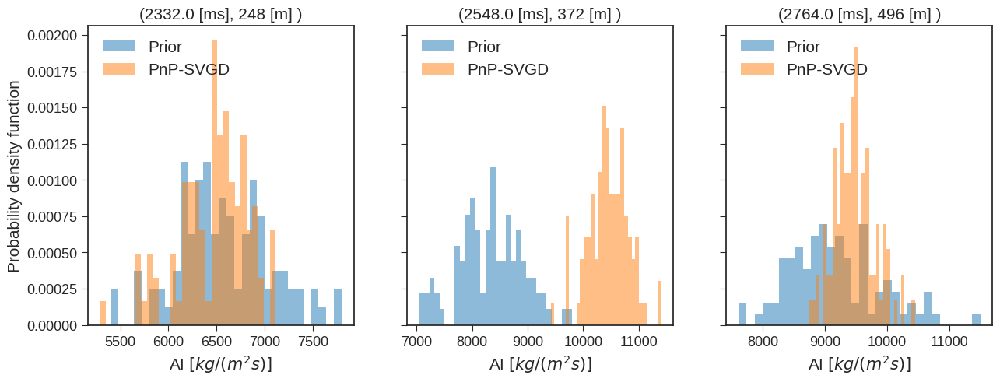

In [24]:
fig, axs = plt.subplots(1, 3, sharey=True, figsize=(15, 5))
num_bins = 30
axs[0].hist(np.exp(X_init).reshape(num_particles, nt, nfence)[:, nt//3, nfence//3], 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[0].hist(np.exp(X).reshape(num_particles, nt, nfence)[:, nt//3, nfence//3], 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[0].set_xlabel(r'AI $[kg/(m^2s)]$')
axs[0].set_ylabel('Probability density function')
axs[0].set_title(f'({t_cut[nt//3]} [ms], {x_seis[nfence//3]} [m] )')
axs[0].set_aspect('auto', 'datalim')
axs[0].legend(loc='upper left')


axs[1].hist(np.exp(X_init).reshape(num_particles, nt, nfence)[:, nt//2, nfence//2], 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[1].hist(np.exp(X).reshape(num_particles, nt, nfence)[:, nt//2, nfence//2], 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[1].set_xlabel(r'AI $[kg/(m^2s)]$')
# axs[1].set_ylabel('Probability density function')
axs[1].set_title(f'({t_cut[nt//2]} [ms], {x_seis[nfence//2]} [m] )')
axs[1].set_aspect('auto', 'datalim')
axs[1].legend(loc='upper left')

axs[2].hist(np.exp(X_init).reshape(num_particles, nt, nfence)[:, 2*nt//3, 2*nfence//3], 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[2].hist(np.exp(X).reshape(num_particles, nt, nfence)[:, 2*nt//3, 2*nfence//3], 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[2].set_xlabel(r'AI $[kg/(m^2s)]$')
# axs[2].set_ylabel('Probability density function')
axs[2].set_title(f'({t_cut[2*nt//3]} [ms], {x_seis[2*nfence//3]} [m] )')
axs[2].set_aspect('auto', 'datalim')
axs[2].legend(loc='upper left')

# plt.savefig('../figures/volve/3-2-volve-hist.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-hist.png', dpi=300, bbox_inches="tight")

Text(0, 0.5, '$t [ms]$')

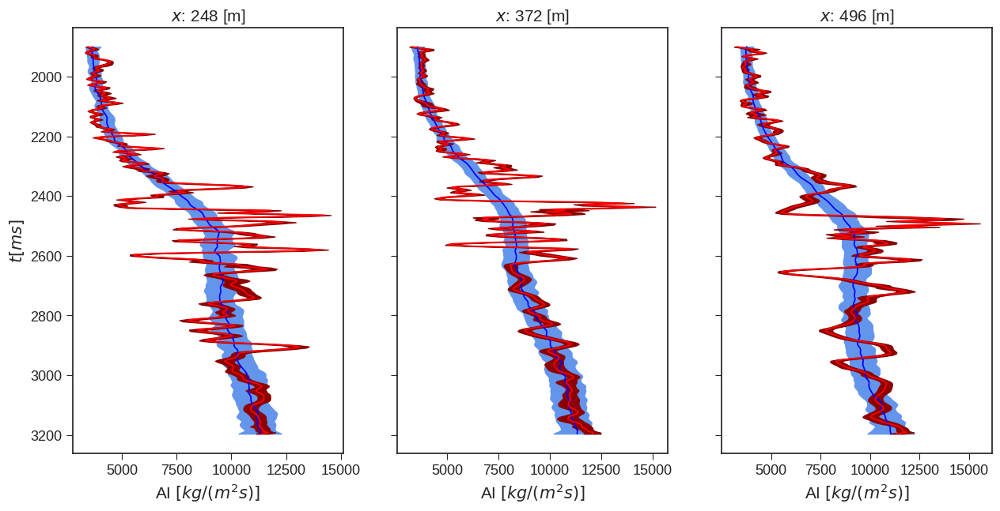

In [25]:
X_initmean, X_initstd = np.exp(X_init).mean(0), np.exp(X_init).std(0)
Xmean, Xstd = np.exp(X).mean(0), np.exp(X).std(0)

fig, axs = plt.subplots(1, 3, sharey=True, figsize=(15, 7))

for i, ix in enumerate([nfence//3, nfence//2, 2*nfence//3]):
    axs[i].plot(X_initmean.reshape(nt, nfence)[:, ix], t_cut, 'b', linewidth=1.25)
    axs[i].fill_betweenx(t_cut, 
                        X_initmean.reshape(nt, nfence)[:, ix] - 
                        X_initstd.reshape(nt, nfence)[:, ix], 
                        X_initmean.reshape(nt, nfence)[:, ix] + 
                        X_initstd.reshape(nt, nfence)[:, ix],
                        color='cornflowerblue')
    axs[i].plot(Xmean.reshape(nt, nfence)[:, ix], t_cut, 'r', linewidth=1.25)
    axs[i].fill_betweenx(t_cut, 
                        Xmean.reshape(nt, nfence)[:, ix] - 
                        Xstd.reshape(nt, nfence)[:, ix], 
                        Xmean.reshape(nt, nfence)[:, ix] + 
                        Xstd.reshape(nt, nfence)[:, ix],
                        color='darkred')
    axs[i].set_xlabel(r'AI $[kg/(m^2s)]$')
    axs[i].set_title(f'$x$: {ix} [m]', fontsize=15)
    axs[i].set_aspect('auto', 'datalim')
axs[0].invert_yaxis()
axs[0].set_ylabel(r'$t [ms]$')
# plt.savefig('../figures/volve/3-2-volve-traces.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-traces.png', dpi=300, bbox_inches="tight")

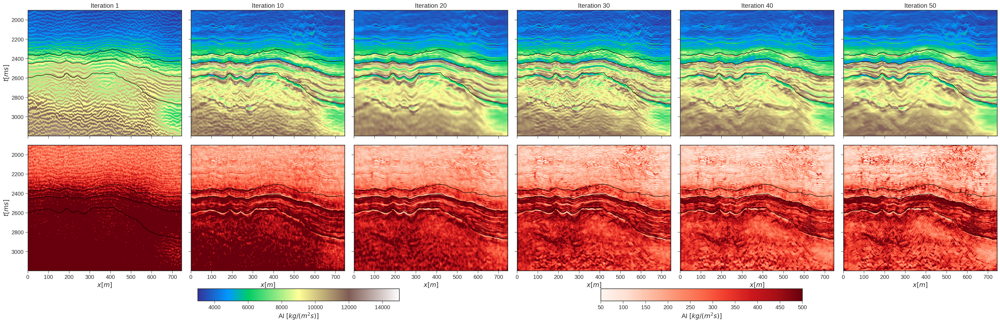

In [26]:
iiter = np.array([1, 10, 20, 30, 40, 50])
fig, axs = plt.subplots(2, 6, sharex=True, sharey=True, figsize=(33,10), dpi=150)
vmin, vmax = 3000, 15000
for i, k in enumerate(iiter):
    axi=axs[0, i].imshow(Xmeancol[i].reshape(nt, nfence), vmin=vmin, vmax=vmax, cmap="terrain",
                     interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
    for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
        axs[0, i].plot(x_seis, horizons_fence[horname], 'k', lw=1)
    axs[0, i].set_title('Iteration %d' % k, fontsize=15)
    axs[0, i].axis('tight')
    axs[0, i].set_aspect('auto', 'datalim')
#     axs[0, i].set_xlabel(r'$x [m]$')
    if i == 0: axs[0, 0].set_ylabel(r'$t [ms]$')

vmin, vmax = 50, 500
for i, k in enumerate(iiter):
    axi2=axs[1, i].imshow(Xstdcol[i].reshape(nt, nfence), vmin=vmin, vmax=vmax, cmap='Reds',
                     interpolation='sinc', extent=(x_seis[0], x_seis[-1], t_cut[-1], t_cut[0]))
    for ihor, horname in enumerate(list(horizons_fence.keys())[:3]):
        axs[1, i].plot(x_seis, horizons_fence[horname], 'k', lw=1)
#     axs[1, i].set_title('Iteration %d' % k)
    axs[1, i].axis('tight')
    axs[1, i].set_xlabel(r'$x [m]$')
    axs[1, i].set_aspect('auto', 'datalim')
    if i == 0: axs[1, 0].set_ylabel(r'$t [ms]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)

cbar_ax1 = fig.add_axes([0.2, 0.001, 0.2, 0.04])
cbar1 = fig.colorbar(axi, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'AI $[kg/(m^2s)]$')

cbar_ax2 = fig.add_axes([0.6, 0.001, 0.2, 0.04])
cbar2 = fig.colorbar(axi2, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label(r'AI $[kg/(m^2s)]$')

# plt.savefig('../figures/volve/3-2-volve-evo.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-evo.png', dpi=300, bbox_inches="tight")

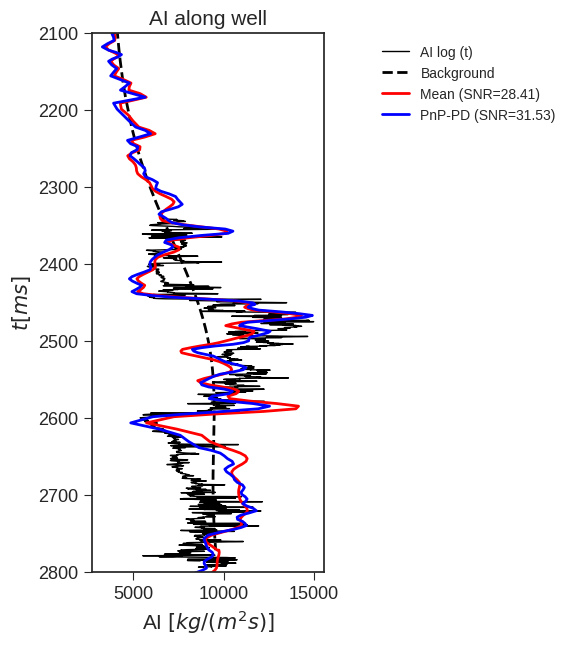

In [27]:
# Interpolate well log at resolution of estimated AI and compare with estimates
minv_t = RegularGridInterpolator((x_seis, t_cut), 
                                 Xmean.numpy().reshape(nt, nfence).T, 
                                 bounds_error=False,
                                 fill_value=np.nan)(np.vstack((xfence_int, twell_int)).T)
nsmooth=5
well_ai_int = np.interp(twell_int, well_twt, well_ai)[1100:1183]

fig, ax = plt.subplots(1, 1, figsize=(3, 7))
ax.plot(filtfilt(np.ones(nsmooth)/nsmooth, 1, well_ai), well_twt, 'k', lw=1, label='AI log (t)')
ax.plot(np.exp(ai_fence_t), twell, '--k', lw=2, label='Background')
ax.plot(minv_t, twell_int, 'r', lw=2, label='Mean (SNR=%.2f)' % snr(well_ai_int, minv_t[1100:1183]))
ax.plot(mdrunet_t, twell_int, 'b', lw=2, label='PnP-PD (SNR=%.2f)' % snr(well_ai_int, mdrunet_t[1100:1183]))
ax.invert_yaxis()
ax.set_title('AI along well', fontsize=15)
ax.set_ylabel(r'$t [ms]$')
ax.set_xlabel(r'AI $[kg/(m^2s)]$')
ax.set_ylim(2800, 2100)
ax.set_aspect('auto', 'datalim')
leg = ax.legend(loc=1, prop={'size': 10}, bbox_to_anchor=(2.05, 1 ))
# plt.savefig('../figures/volve/3-2-volve-well-log.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/volve/3-2-volve-well-log.png', dpi=300, bbox_inches="tight")